In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.calibration import calibration_curve

features = pd.read_pickle("../data/features_wc2018.pkl")

X = features[["distance", "angle"]]
y = features["goal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape, y_train.mean(), y_test.mean())

(1228, 2) (410, 2) 0.08224755700325732 0.08292682926829269


In [2]:
model = LogisticRegression()
model.fit(X_train, y_train)

test_probs = model.predict_proba(X_test)[:, 1]
print("Log loss:", log_loss(y_test, test_probs))
print("ROC AUC:", roc_auc_score(y_test, test_probs))

Log loss: 0.25133805393081926
ROC AUC: 0.7505475594493116


In [3]:
sb_probs = features.loc[X_test.index, "shot_statsbomb_xg"]
print("StatsBomb log loss:", log_loss(y_test, sb_probs))
print("StatsBomb ROC AUC:", roc_auc_score(y_test, sb_probs))

StatsBomb log loss: 0.2458232292780503
StatsBomb ROC AUC: 0.7712765957446809


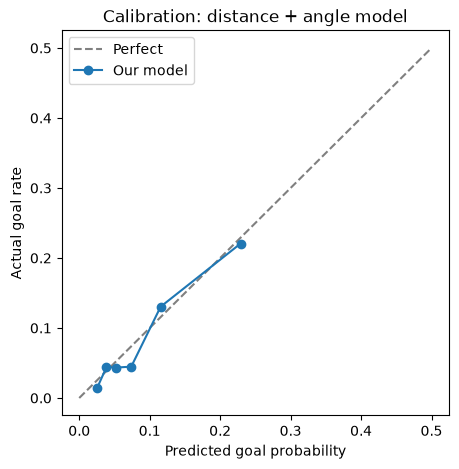

In [4]:
frac_pos, mean_pred = calibration_curve(y_test, test_probs, n_bins=6, strategy="quantile")

plt.figure(figsize=(5, 5))
plt.plot([0, 0.5], [0, 0.5], "--", color="gray", label="Perfect")
plt.plot(mean_pred, frac_pos, marker="o", label="Our model")
plt.xlabel("Predicted goal probability")
plt.ylabel("Actual goal rate")
plt.legend()
plt.title("Calibration: distance + angle model")
plt.savefig("../figures/calibration_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import log_loss, roc_auc_score

features = pd.read_pickle("../data/features_wc2018.pkl")
y = features["goal"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Feature set 2: add header flag and shot type
X2 = features[["distance", "angle", "is_header"]].copy()
X2 = X2.join(pd.get_dummies(features["shot_type"], prefix="type").astype(int))

def evaluate(model, X, name):
    p = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 1]
    print(f"{name:35s} log loss {log_loss(y, p):.4f} | AUC {roc_auc_score(y, p):.4f}")
    return p

# No-skill reference: everyone gets the average goal rate
base_rate = np.full(len(y), y.mean())
print(f"{'Constant (no skill)':35s} log loss {log_loss(y, base_rate):.4f}")

evaluate(LogisticRegression(max_iter=1000), features[["distance", "angle"]], "Logistic: distance + angle")
evaluate(LogisticRegression(max_iter=1000), X2, "Logistic: + header + shot type")
evaluate(GradientBoostingClassifier(n_estimators=100, max_depth=2, learning_rate=0.05, random_state=42),
         X2, "Gradient boosting: all features")

sb = features["shot_statsbomb_xg"]
print(f"{'StatsBomb xG':35s} log loss {log_loss(y, sb):.4f} | AUC {roc_auc_score(y, sb):.4f}")

Constant (no skill)                 log loss 0.2846
Logistic: distance + angle          log loss 0.2535 | AUC 0.7360
Logistic: + header + shot type      log loss 0.2490 | AUC 0.7557
Gradient boosting: all features     log loss 0.2602 | AUC 0.7135
StatsBomb xG                        log loss 0.2373 | AUC 0.7815


In [6]:
f2 = pd.read_pickle("../data/features_v2_wc2018.pkl").dropna(subset=["defenders_in_cone", "gk_dist_to_goal"])
y2 = f2["goal"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

base_cols = ["distance", "angle", "is_header"]
X_a = f2[base_cols].join(pd.get_dummies(f2["shot_type"], prefix="type").astype(int))
X_b = X_a.join(f2[["defenders_in_cone", "gk_dist_to_goal", "nearest_defender"]])

def evaluate2(model, X, name):
    p = cross_val_predict(model, X, y2, cv=cv, method="predict_proba")[:, 1]
    print(f"{name:35s} log loss {log_loss(y2, p):.4f} | AUC {roc_auc_score(y2, p):.4f}")

evaluate2(LogisticRegression(max_iter=2000), X_a, "Logistic: v1 features")
evaluate2(LogisticRegression(max_iter=2000), X_b, "Logistic: + freeze-frame")
print(f"{'StatsBomb xG':35s} log loss {log_loss(y2, f2.shot_statsbomb_xg):.4f} | AUC {roc_auc_score(y2, f2.shot_statsbomb_xg):.4f}")

Logistic: v1 features               log loss 0.2512 | AUC 0.7496
Logistic: + freeze-frame            log loss 0.2439 | AUC 0.7613
StatsBomb xG                        log loss 0.2374 | AUC 0.7815


In [7]:
p_final = cross_val_predict(
    LogisticRegression(max_iter=2000), X_b, y2, cv=cv, method="predict_proba"
)[:, 1]

f2 = f2.copy()
f2["my_xg"] = p_final
f2[["player", "team", "goal", "my_xg", "shot_statsbomb_xg"]].head()

,player,team,goal,my_xg,shot_statsbomb_xg
0,Kevin De Bruyne,Belgium,0,0.029101,0.020461
1,Thiago Emiliano da Silva,Brazil,0,0.415001,0.274021
2,Eden Hazard,Belgium,0,0.036962,0.065900
3,Nacer Chadli,Belgium,0,0.013029,0.022908
4,José Paulo Bezzera Maciel Júnior,Brazil,0,0.112502,0.174216


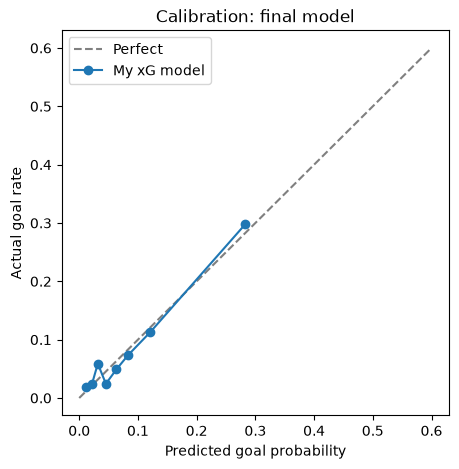

In [8]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

frac_pos, mean_pred = calibration_curve(y2, p_final, n_bins=8, strategy="quantile")

plt.figure(figsize=(5, 5))
plt.plot([0, 0.6], [0, 0.6], "--", color="gray", label="Perfect")
plt.plot(mean_pred, frac_pos, marker="o", label="My xG model")
plt.xlabel("Predicted goal probability")
plt.ylabel("Actual goal rate")
plt.title("Calibration: final model")
plt.legend()
plt.savefig("../figures/calibration_final.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
players = (f2.groupby("player")
             .agg(shots=("goal", "size"),
                  goals=("goal", "sum"),
                  my_xg=("my_xg", "sum"),
                  sb_xg=("shot_statsbomb_xg", "sum"))
             .query("shots >= 8"))
players["goals_minus_xg"] = players.goals - players.my_xg
players.sort_values("goals_minus_xg", ascending=False).round(2)

,shots,goals,my_xg,sb_xg,goals_minus_xg
player,,,,,
Denis Cheryshev,13,4,0.89,1.11,3.11
Kylian Mbappé Lottin,8,4,1.83,1.78,2.17
Cristiano Ronaldo dos Santos Aveiro,20,3,1.20,1.14,1.80
Harry Kane,11,3,1.24,1.68,1.76
Romelu Lukaku Menama,14,4,2.27,2.61,1.73
Takashi Inui,9,2,0.38,0.55,1.62
Edinson Roberto Cavani Gómez,16,3,1.98,2.15,1.02
Ivan Perišić,24,3,1.99,2.11,1.01
Juan Fernando Quintero Paniagua,8,1,0.22,0.22,0.78


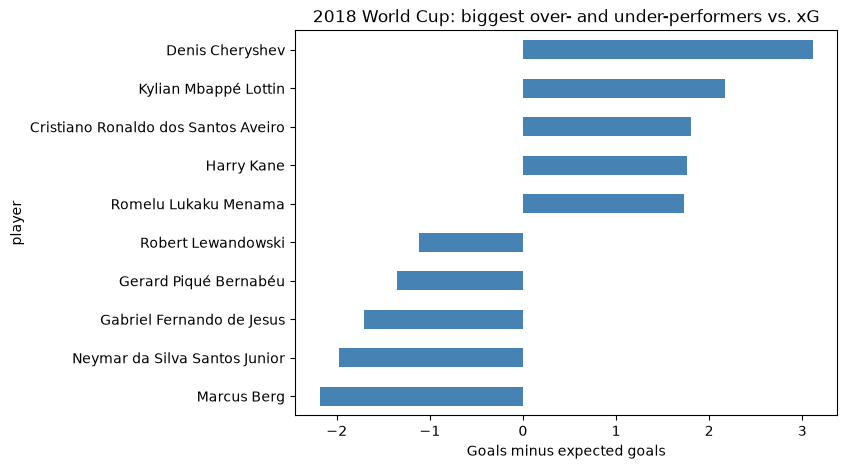

In [10]:
top = players.sort_values("goals_minus_xg").iloc[[0, 1, 2, 3, 4, -5, -4, -3, -2, -1]]
top["goals_minus_xg"].plot.barh(figsize=(7, 5), color="steelblue")
plt.xlabel("Goals minus expected goals")
plt.title("2018 World Cup: biggest over- and under-performers vs. xG")
plt.savefig("../figures/over_under_performers.png", dpi=150, bbox_inches="tight")
plt.show()

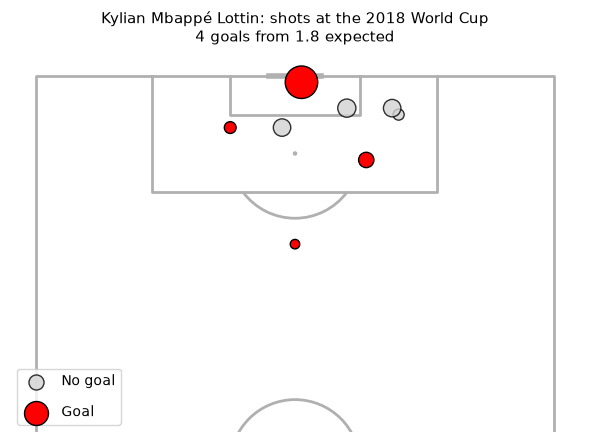

In [11]:
from mplsoccer import VerticalPitch

def shot_map(player_name, save_as=None):
    d = f2[f2.player == player_name]
    pitch = VerticalPitch(pitch_type="statsbomb", half=True, pad_bottom=-5)
    fig, ax = pitch.draw(figsize=(6, 6))

    misses = d[d.goal == 0]
    goals = d[d.goal == 1]
    pitch.scatter(misses.x, misses.y, s=misses.my_xg * 600 + 30, ax=ax,
                  c="lightgray", edgecolors="black", alpha=0.8, label="No goal")
    pitch.scatter(goals.x, goals.y, s=goals.my_xg * 600 + 30, ax=ax,
                  c="red", edgecolors="black", label="Goal")

    ax.set_title(f"{player_name}: shots at the 2018 World Cup\n"
                 f"{int(d.goal.sum())} goals from {d.my_xg.sum():.1f} expected", fontsize=11)
    ax.legend(loc="lower left", labelspacing=1.2)
    if save_as:
        fig.savefig(save_as, dpi=150, bbox_inches="tight")
    plt.show()

shot_map("Kylian Mbappé Lottin", save_as="../figures/shotmap_mbappe.png")

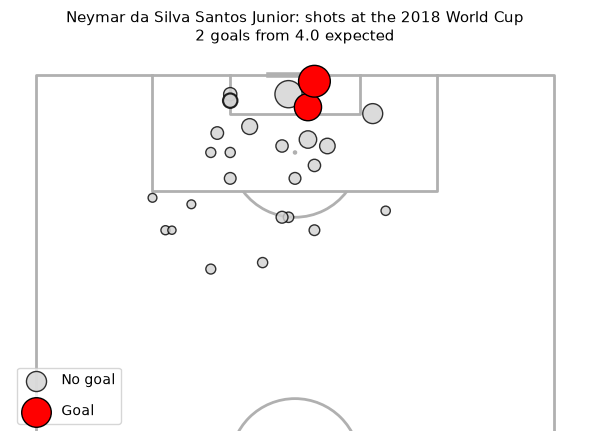

In [12]:
from mplsoccer import VerticalPitch

def shot_map(player_name, save_as=None):
    d = f2[f2.player == player_name]
    pitch = VerticalPitch(pitch_type="statsbomb", half=True, pad_bottom=-5)
    fig, ax = pitch.draw(figsize=(6, 6))

    misses = d[d.goal == 0]
    goals = d[d.goal == 1]
    pitch.scatter(misses.x, misses.y, s=misses.my_xg * 600 + 30, ax=ax,
                  c="lightgray", edgecolors="black", alpha=0.8, label="No goal")
    pitch.scatter(goals.x, goals.y, s=goals.my_xg * 600 + 30, ax=ax,
                  c="red", edgecolors="black", label="Goal")

    ax.set_title(f"{player_name}: shots at the 2018 World Cup\n"
                 f"{int(d.goal.sum())} goals from {d.my_xg.sum():.1f} expected", fontsize=11)
    ax.legend(loc="lower left", labelspacing=1.2)
    if save_as:
        fig.savefig(save_as, dpi=150, bbox_inches="tight")
    plt.show()

shot_map("Neymar da Silva Santos Junior", save_as="../figures/shotmap_mbappe.png")